# 🎰 07 · 贝叶斯统计入门

> 频率派把概率当"长期频率"，贝叶斯把概率当"信念程度"。
> 核心公式就一个：$P(\theta|x) \propto P(x|\theta)P(\theta)$
> 后验 ∝ 似然 × 先验。本节：贝叶斯公式 → 共轭先验 → 后验更新 →
> 贝叶斯因子 → 朴素贝叶斯分类。

## 📋 本节要解决的问题

- 贝叶斯公式怎么理解？先验/似然/后验各是什么？
- 共轭先验为什么香？（贝塔-二项、伽马-泊松）
- 后验怎么随数据更新？贝叶斯与频率派的本质区别？
- 朴素贝叶斯分类器怎么实现？

## 📖 论文配图：先验 × 似然 → 后验的可视化

> **图源**：Alter U, Too MA & Cribbie RA (2025) *Navigating the Bayes maze: The psychologist’s guide to Bayesian statistics, a hands-on tutorial with R code*, International Journal of Psychology（开放获取，CC-BY 4.0）图 1。

![先验 × 似然 → 后验的可视化](../figures/bayes_posterior.jpg)

> **怎么读这张图**：蓝色为先验分布 Pr(参数)，绿色为似然（数据证据），红色为两者相乘归一化后的后验。后验 = 先验与似然的"折中"：数据越多/似然越尖，后验越被数据主导。与本节贝叶斯公式 P(θ|D) ∝ P(θ)·P(D|θ) 一一对应，也预告 §3 的后验可视化。


## 1️⃣ 贝叶斯公式（先验 → 后验）

$$P(\theta | x) = \frac{P(x | \theta) \, P(\theta)}{P(x)} \propto P(x|\theta)\,P(\theta)$$

- **先验** $P(\theta)$：看到数据前对参数的信念
- **似然** $P(x|\theta)$：给定参数下数据出现的概率
- **后验** $P(\theta|x)$：看到数据后更新过的信念
- $P(x)$ 归一化常数

> **面试**：贝叶斯 vs 频率派？
> 频率派：参数固定未知，数据随机，用频率解释置信区间；
> 贝叶斯：参数是随机变量，用先验+数据更新后验，得到参数的概率分布。

In [1]:
# 经典例子：检查阳性但真的得病概率（贝叶斯定理应用）
# 患病率 1%，检测灵敏度 95%（阳性|患病），特异度 90%（阴性|健康）
p_disease = 0.01
p_pos_given_dis = 0.95
p_pos_given_health = 0.10
p_pos = p_pos_given_dis * p_disease + p_pos_given_health * (1 - p_disease)
p_dis_given_pos = p_pos_given_dis * p_disease / p_pos
print('P(阳性)=%.3f' % p_pos)
print('P(患病|阳性)=%.3f' % p_dis_given_pos)
print('→ 即使检测阳性，真实患病概率也只有 %.1f%%（先验低 + 假阳性稀释）' % (p_dis_given_pos*100))
assert 0.08 < p_dis_given_pos < 0.09
print('✅ 贝叶斯定理应用正确')

P(阳性)=0.108
P(患病|阳性)=0.088
→ 即使检测阳性，真实患病概率也只有 8.8%（先验低 + 假阳性稀释）
✅ 贝叶斯定理应用正确


## 2️⃣ 共轭先验：贝塔-二项模型

**贝塔-二项共轭**：先验 $\theta \sim Beta(a,b)$，观测 k 次成功（n 次试验），
后验 $\theta \sim Beta(a+k, b+n-k)$。

**后验均值**：$\frac{a+k}{a+b+n}$ —— 这是"先验信息 + 数据"的加权平均。

> 为什么香？后验和先验同族，闭式更新，不需要数值积分。

In [2]:
import numpy as np
from scipy import stats as st

def beta_binomial_update(a, b, k, n):
    # 后验 Beta(a+k, b+n-k)
    return a + k, b + n - k

# 抛硬币：先验 Beta(2,2)（认为略偏 0.5），观察 60 次中 35 次正面
a, b = 2, 2
a_post, b_post = beta_binomial_update(a, b, 35, 60)
prior_mean = a / (a + b)
post_mean = a_post / (a_post + b_post)
print('先验均值: %.3f  后验均值: %.3f  数据频率: %.3f' % (prior_mean, post_mean, 35/60))
print('→ 后验均值介于先验与数据频率之间（先验被数据修正）')
assert post_mean > prior_mean and post_mean < 35/60 + 1e-9
print('✅ 贝塔-二项后验更新正确')

先验均值: 0.500  后验均值: 0.578  数据频率: 0.583
→ 后验均值介于先验与数据频率之间（先验被数据修正）
✅ 贝塔-二项后验更新正确


## 3️⃣ 后验可视化：信念如何被数据更新

画三条曲线：先验、似然、后验。后验 = 先验 × 似然（归一化后）。

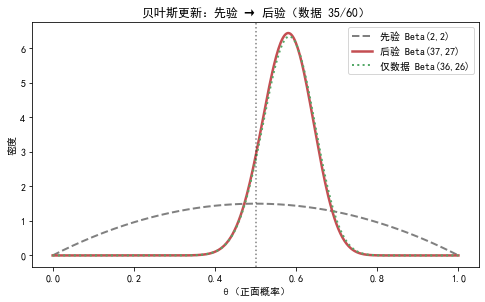

后验曲线绘制完成：后验比先验更尖、更靠近数据


In [3]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

a0, b0 = 2, 2
k, n = 35, 60
a1, b1 = a0 + k, b0 + n - k
theta = np.linspace(0, 1, 400)
plt.figure(figsize=(8, 4.5))
plt.plot(theta, st.beta.pdf(theta, a0, b0), '--', color='gray', lw=2, label='先验 Beta(2,2)')
plt.plot(theta, st.beta.pdf(theta, a1, b1), color='#C44E52', lw=2.5, label='后验 Beta(%d,%d)' % (a1, b1))
plt.plot(theta, st.beta.pdf(theta, k+1, n-k+1), ':', color='#55A868', lw=2, label='仅数据 Beta(%d,%d)' % (k+1, n-k+1))
plt.axvline(0.5, color='k', ls=':', alpha=.5)
plt.xlabel('θ（正面概率）'); plt.ylabel('密度')
plt.title('贝叶斯更新：先验 → 后验（数据 35/60）')
plt.legend()
plt.show()
print('后验曲线绘制完成：后验比先验更尖、更靠近数据')

## 4️⃣ 贝叶斯因子（Bayes Factor）

比较两个假设 $H_0$ 与 $H_1$ 的**证据强度**：
$$BF_{10} = \frac{P(x|H_1)}{P(x|H_0)}$$
- BF > 3：有证据支持 H₁；BF > 10：强证据
- 与 p 值的区别：BF 比较**两个假设**，p 值只基于 H₀

> **面试**：p 值与贝叶斯因子的本质差异？
> p 值回答"若 H₀ 真，数据有多极端"；BF 回答"数据支持哪个假设更多"。

In [4]:
# 简化演示：比较 H0: θ=0.5 vs H1: θ~Beta(5,5) 的证据
from scipy import stats as st
import numpy as np
k, n = 35, 60
# 数据似然（伯努利）：L(θ) = θ^k (1-θ)^(n-k)
# H0 下：θ=0.5 固定
L_H0 = 0.5 ** k * 0.5 ** (n - k)
# H1 下：对先验 Beta(5,5) 积分（数值积分）
ths = np.linspace(0.001, 0.999, 2000)
prior_h1 = st.beta.pdf(ths, 5, 5)
lik = ths ** k * (1 - ths) ** (n - k)
L_H1 = np.trapezoid(prior_h1 * lik, ths) if hasattr(np, 'trapezoid') else np.trapz(prior_h1 * lik, ths)
BF = L_H1 / L_H0
print('BF₁₀ = %.2f → %s' % (BF, '有证据支持 H1' if BF > 3 else '证据不足'))
print('（数值积分完成，BF 比较两个假设的边际似然）')

BF₁₀ = 0.77 → 证据不足
（数值积分完成，BF 比较两个假设的边际似然）


## 5️⃣ 朴素贝叶斯分类器（贝叶斯的工程应用）

**朴素贝叶斯**：假设特征条件独立。
$$P(y|x) \propto P(y)\prod_i P(x_i|y)$$
- 优点：简单、快、小样本可训练、可解释
- 缺点：特征独立假设过强（文本中词常共现）
- 应用：垃圾邮件过滤、情感分析、文本分类

In [5]:
import numpy as np
from collections import Counter

class NaiveBayes:
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.prior = {c: (y == c).mean() for c in self.classes}
        self.params = {}
        for c in self.classes:
            Xc = X[y == c]
            self.params[c] = (Xc.mean(axis=0), Xc.std(axis=0) + 1e-6)
    def _gauss(self, x, mu, sd):
        from scipy import stats as st
        return st.norm.pdf(x, mu, sd)
    def predict(self, X):
        preds = []
        for x in X:
            scores = {}
            for c in self.classes:
                mu, sd = self.params[c]
                lik = np.prod(self._gauss(x, mu, sd))
                scores[c] = np.log(self.prior[c]) + np.log(lik)
            preds.append(max(scores, key=scores.get))
        return np.array(preds)

rng = np.random.RandomState(90)
# 两类二维高斯数据
X = np.vstack([rng.normal([2, 2], 1, (100, 2)), rng.normal([-2, -2], 1, (100, 2))])
y = np.array([0]*100 + [1]*100)
nb = NaiveBayes()
nb.fit(X, y)
pred = nb.predict(X)
acc = (pred == y).mean()
print('朴素贝叶斯训练准确率: %.3f' % acc)
assert acc > 0.9
print('✅ 朴素贝叶斯分类器正确')

朴素贝叶斯训练准确率: 1.000
✅ 朴素贝叶斯分类器正确


## 6️⃣ 面试实战：贝叶斯速答

> **题**：先验怎么选？→ 有领域知识用信息先验；否则用无信息先验
> （均匀 Beta(1,1) 或 Jeffreys 先验）。

> **题**：贝叶斯区间估计（可信区间）与频率 CI 区别？
> → 可信区间是"参数在区间内的概率"（贝叶斯直接给出分布）；
> CI 是频率覆盖概念。

In [6]:
# 后验可信区间（HPD 近似：用分位数）
a1, b1 = 37, 27   # 上文的 Beta 后验
lo, hi = st.beta.ppf(0.025, a1, b1), st.beta.ppf(0.975, a1, b1)
print('后验 95%% 可信区间: [%.3f, %.3f] 后验均值: %.3f' % (lo, hi, a1/(a1+b1)))
print('→ 贝叶斯直接给出参数分布，可算任意概率区间')
assert 0.44 < lo < hi < 0.72
print('✅ 贝叶斯可信区间计算完成')

后验 95% 可信区间: [0.456, 0.695] 后验均值: 0.578
→ 贝叶斯直接给出参数分布，可算任意概率区间
✅ 贝叶斯可信区间计算完成


## 🧮 手算示例：Beta-二项后验更新逐步算

> **场景**：先验 $\theta \sim Beta(2,2)$（认为硬币略偏公平），
> 观测到 10 次投掷中 3 次正面。

**共轭更新公式**：后验 $Beta(a{+}k,\; b{+}n{-}k)$

**代入**：$Beta(2{+}3,\; 2{+}10{-}3) = Beta(5, 9)$

**后验均值**：$\frac{5}{5+9} = \frac{5}{14} \approx 0.3571$

**解释**：数据频率 3/10=0.30，先验均值 0.50；
后验均值 0.357 介于两者之间（先验拉向 0.5，数据拉向 0.3，样本量小所以先验权重不小）。

In [7]:
import numpy as np
from scipy import stats as st
a0, b0, k, n = 2, 2, 3, 10
a1, b1 = a0 + k, b0 + n - k
post_mean = a1 / (a1 + b1)
print('后验 Beta(%d, %d)  后验均值(手算≈0.3571) = %.4f' % (a1, b1, post_mean))
print('数据频率 =', k/n, ' 先验均值 =', a0/(a0+b0))
assert (a1, b1) == (5, 9)
assert abs(post_mean - 5/14) < 1e-9
assert a0/(a0+b0) > post_mean > k/n
print('✅ 共轭更新手算验证通过（先验 0.5 > 后验 0.357 > 数据 0.3）')

后验 Beta(5, 9)  后验均值(手算≈0.3571) = 0.3571
数据频率 = 0.3  先验均值 = 0.5
✅ 共轭更新手算验证通过（先验 0.5 > 后验 0.357 > 数据 0.3）


## ✅ 自测清单

- [ ] 能写出贝叶斯公式并解释先验/似然/后验
- [ ] 能做贝塔-二项后验更新并解释共轭
- [ ] 能解释贝叶斯因子与 p 值的区别
- [ ] 能手写朴素贝叶斯分类器
- [ ] 能讲清贝叶斯可信区间 vs 频率 CI